## Visulations of Results

This notebook sets out to bring the work to life - displaying some images differing in princiapal components and analysing what happens to explained variance ratios and predictions as we increase the number of principal components.

In [3]:
from src.pca import Eigendigits
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
from sklearn.model_selection import train_test_split

data = pd.read_csv('data/mnist.csv')
Y = np.array(data["digit"]) # selecting the column called digit
X = np.array(data.drop("digit", axis=1).copy())

X_train, X_test, y_train, y_test = train_test_split(X, Y, test_size=0.2, random_state=42)

### Quick demo of how to use the Eigendigits class

In [4]:
# creating an Eigendigits object 
obj = Eigendigits(20)
obj.fit(X_train)
print(obj)

Eigendigits object
Number of principal components: 20
Explained variance ratio: 0.6525931091740685


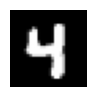

In [5]:
# picking a random image from the dataset and displaying it  
z_0 = X[58]

z_0_reshaped = z_0.reshape(28,28)
plt.figure(figsize=(1,1))
plt.imshow(z_0_reshaped, cmap='gray')
plt.axis('off')
plt.show()

In [6]:
#should equal 4 as is displayed above - here z_0 is from the training data so will be exact. This is not the case later on. 
obj.classify(X, Y, z_0)

np.int64(4)

The same image again using the principal components. 

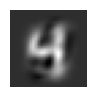

In [7]:
# projection 
z_0_projected = obj.project(X)[58]

z_0_projected = z_0_projected.reshape(28,28)
plt.figure(figsize=(1,1))
plt.imshow(z_0_projected, cmap='gray')
plt.axis('off')
plt.show()

In [8]:
def accuracy(X_test):
    """
    func for calculating the accuracy of the test set 
    """

    predictions = []
    correct_count = 0
    for idx, row in enumerate(X_test):
        x_test = row
        prediction =  obj.classify(X_train, y_train, x_test)
        predictions.append(prediction)
        if prediction == y_test[idx]:
            correct_count += 1

    return correct_count/X_test.shape[0]

Iterating over the test set, plotting the explained variance ratio and accuracy for differing numbers of principal components.

In [ ]:
evr_list = []
accuracy_list = []
x_axes = np.geomspace(1, X_train.shape[1], 11)

for n_pcs in x_axes:
    n_pcs = int(n_pcs)

    obj = Eigendigits(n_pcs)
    obj.fit(X_train)
    evr_list.append(obj.explained_variance_ratio)
    accuracy_list.append(accuracy(X_test))


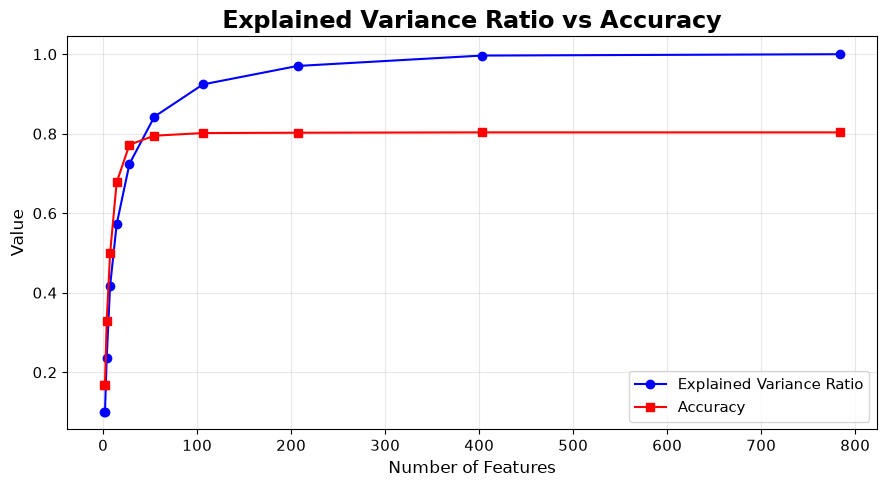

In [ ]:
fig, ax = plt.subplots(figsize=(9, 5))

# Explained variance ratio
ax.plot(x_axes, evr_list, 'b-o', label='Explained Variance Ratio')

# Accuracy
ax.plot(x_axes, accuracy_list, 'r-s', label='Accuracy')

ax.set_xlabel('Number of Features')
ax.set_ylabel('Value')

ax.set_title('Explained Variance Ratio vs Accuracy')

ax.legend()
ax.grid(alpha=0.3)

fig.tight_layout()
plt.show()

Interestingly, accuracy only increases up to a point. This highlights an important distinction between dimensionality reduction and classification performance. The fast increases at the start make sense as the first principal components contain the most variance. It seems the first 80 components cpature most of the information needed to distinguish between digits. Components beyond 80 may capture variances such as small differences in handwriting, pixel noise, or positioning rather than useful distinguishing features.

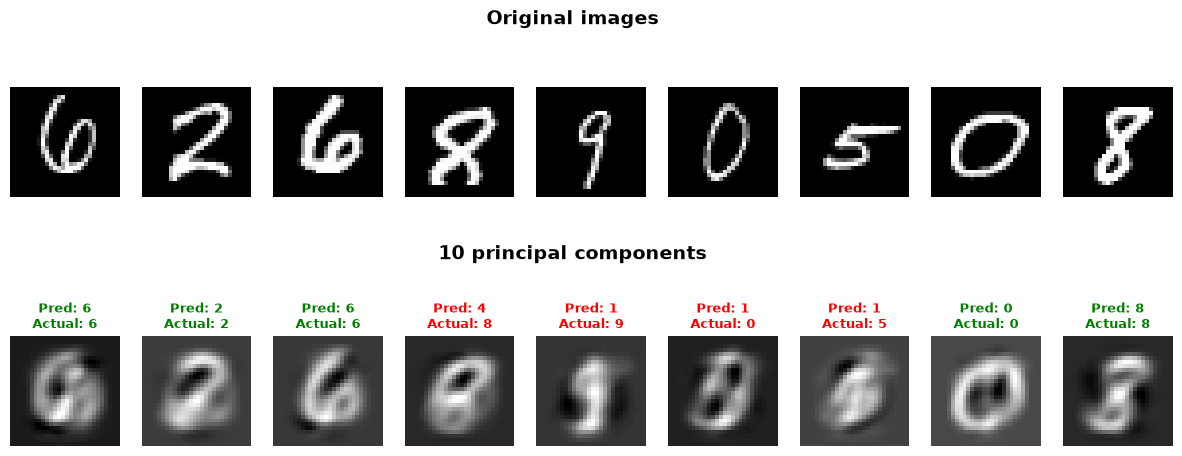

In [ ]:
obj = Eigendigits(10)
obj.fit(X_train)

X_test_projected = obj.project(X_test[:9])

y_pred = []

for i, row in enumerate(X_test):
    prediction = obj.classify(X_train, y_train, row)
    y_pred.append(prediction)

train_samples = X_test[:9]
test_samples = X_test_projected[:9]

fig, axes = plt.subplots(2, 9, figsize=(15, 5))

# First row: Original images
for i in range(9):
    axes[0, i].imshow(train_samples[i].reshape(28, 28), cmap='gray')
    axes[0, i].axis('off')

# Second row: Images reconstructed using 10 principal components
for i in range(9):
    axes[1, i].imshow(test_samples[i].reshape(28, 28), cmap='gray')
    axes[1, i].axis('off')

    # Display predicted and actual labels
    axes[1, i].set_title(
        f'Pred: {y_pred[i]}\nActual: {y_test[i]}',
        fontsize=9,
        color='green' if y_pred[i] == y_test[i] else 'red'
    )

# Horizontal row headers
fig.text(0.5, 0.95, 'Original images',
         ha='center', fontsize=14, fontweight='bold')

fig.text(0.5, 0.48, '10 principal components',
         ha='center', fontsize=14, fontweight='bold')

plt.subplots_adjust(top=0.88, bottom=0.05, hspace=0.5)
plt.show()